# Comparación, hiperparámetros y evaluación congelada

Estos notebooks documentan experimentos ejecutados y leen sus artefactos. El entrenamiento completo se reproduce con `scripts/run_experiments.py`; las celdas de revisión no ajustan modelos ni cambian la selección. El informe final y la presentación corresponden a una etapa posterior.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
OUT = ROOT / 'outputs'
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 30)
protocol = json.loads((ROOT/'experiments'/'protocol.json').read_text(encoding='utf-8'))

## Familias y búsqueda temporal

Regresión logística, bagging con Random Forest y boosting con LightGBM, XGBoost y CatBoost. Todas usan el mismo contrato de información previo al desembolso. La búsqueda utiliza exclusivamente los cortes temporales de desarrollo: hasta 80.000 filas de entrenamiento y 40.000 de validación; Random Forest explora hasta 30.000/20.000 por su costo computacional. La selección posterior reentrena todas las familias con las mismas filas completas y las compara sobre la misma cohorte. Los números de intentos incluyen intentos podados; los CSV preservan configuraciones y puntuaciones por corte.

In [2]:
families=['logistic','random_forest','lightgbm','xgboost','catboost']
best=[json.loads((OUT/f'best_{f}.json').read_text(encoding='utf-8')) for f in families]
display(pd.DataFrame(best)[['family','CV_AP','trial_count','fold_AP','fold_best_iterations']])
for row in best:
    print(row['family'], row['params'])

,family,CV_AP,trial_count,fold_AP,fold_best_iterations
0,logistic,0.283392,10,"[0.291927172256824, 0.2748568046449956]","[None, None]"
1,random_forest,0.276079,10,"[0.2795910223757521, 0.27256689909577336]","[None, None]"
2,lightgbm,0.286974,28,"[0.290893463736427, 0.2830535543868771]","[77, 173]"
3,xgboost,0.284971,24,"[0.2903729856277938, 0.27956837836342874]","[91, 476]"
4,catboost,0.290602,24,"[0.29745109012546195, 0.28375341402303833]","[505, 782]"


logistic {'C': 0.013901420350545918, 'class_weight': None}
random_forest {'n_estimators': 250, 'max_depth': 12, 'min_samples_leaf': 60, 'max_features': 'sqrt', 'max_samples': 0.7737068376069123, 'class_weight': 'balanced_subsample'}
lightgbm {'n_estimators': 143, 'learning_rate': 0.05081293756112104, 'num_leaves': 28, 'min_child_samples': 152, 'reg_lambda': 1.4731189846460222, 'reg_alpha': 0.001169714009152734, 'colsample_bytree': 0.6572989610431703, 'subsample': 0.7278140434146148, 'subsample_freq': 1, 'scale_pos_weight': 1.0}
xgboost {'n_estimators': 326, 'learning_rate': 0.04676664740057031, 'max_depth': 3, 'min_child_weight': 6.345356893234593, 'reg_lambda': 7.400833087122808, 'reg_alpha': 2.6202105294222906, 'subsample': 0.701271216187201, 'colsample_bytree': 0.6780273291927688, 'gamma': 0.7056336440801878, 'scale_pos_weight': 2.0}
catboost {'iterations': 740, 'learning_rate': 0.027359299282470315, 'depth': 7, 'l2_leaf_reg': 27.333886656404555, 'random_strength': 1.563510870813345

In [3]:
display(pd.read_csv(OUT/'analysis'/'model_inventory.csv'))

,model,family,extended_features,seed,transformed_columns,trees,selected_weight
0,baseline19,logistic,False,42,97,NaN,0.000000
1,catboost,catboost,True,42,96,740.0,0.200000
2,catboost_seed43,catboost,True,43,96,740.0,0.200000
3,catboost_seed44,catboost,True,44,96,740.0,0.200000
4,lightgbm,lightgbm,True,42,96,143.0,0.133333
5,lightgbm_seed43,lightgbm,True,43,96,143.0,0.133333
6,lightgbm_seed44,lightgbm,True,44,96,143.0,0.133333
7,logistic,logistic,True,42,238,NaN,0.000000
8,random_forest,random_forest,True,42,238,250.0,0.000000
9,xgboost,xgboost,True,42,96,326.0,0.000000


## Selección independiente del ajuste

La selección de familia, semillas y pesos usa 2014 H1, sin acceso a pruebas 2015/2016. Se añade el baseline de 19 variables y una ablación de la mejor familia. Un ensamble requiere al menos 0,001 AP de mejora sobre el mejor modelo individual. La tabla también registra variación por semilla.

In [4]:
display(pd.read_csv(OUT/'selection_leaderboard.csv')[['name','family','AP','ROC_AUC','Brier']])
selection=json.loads((OUT/'selection.json').read_text(encoding='utf-8'))
print('Elección previa a la prueba:', selection['selected'])
print('Pesos:', selection['weights'])

,name,family,AP,ROC_AUC,Brier
0,selected,ensemble,0.340128,0.710807,0.133112
1,catboost,catboost,0.338715,0.710015,0.133142
2,catboost_seed44,catboost,0.338513,0.709838,0.133179
3,catboost_seed43,catboost,0.337821,0.709465,0.133230
4,lightgbm_seed43,lightgbm,0.337043,0.708015,0.133432
5,lightgbm_seed44,lightgbm,0.335605,0.707472,0.133488
6,lightgbm,lightgbm,0.334880,0.707791,0.133507
7,xgboost,xgboost,0.333946,0.706667,0.142678
8,logistic,logistic,0.328770,0.702208,0.133928
9,random_forest,random_forest,0.326208,0.699393,0.216167


Elección previa a la prueba: ensemble
Pesos: {'catboost': 0.19999999999999998, 'catboost_seed43': 0.19999999999999998, 'catboost_seed44': 0.19999999999999998, 'lightgbm': 0.13333333333333333, 'lightgbm_seed43': 0.13333333333333333, 'lightgbm_seed44': 0.13333333333333333}


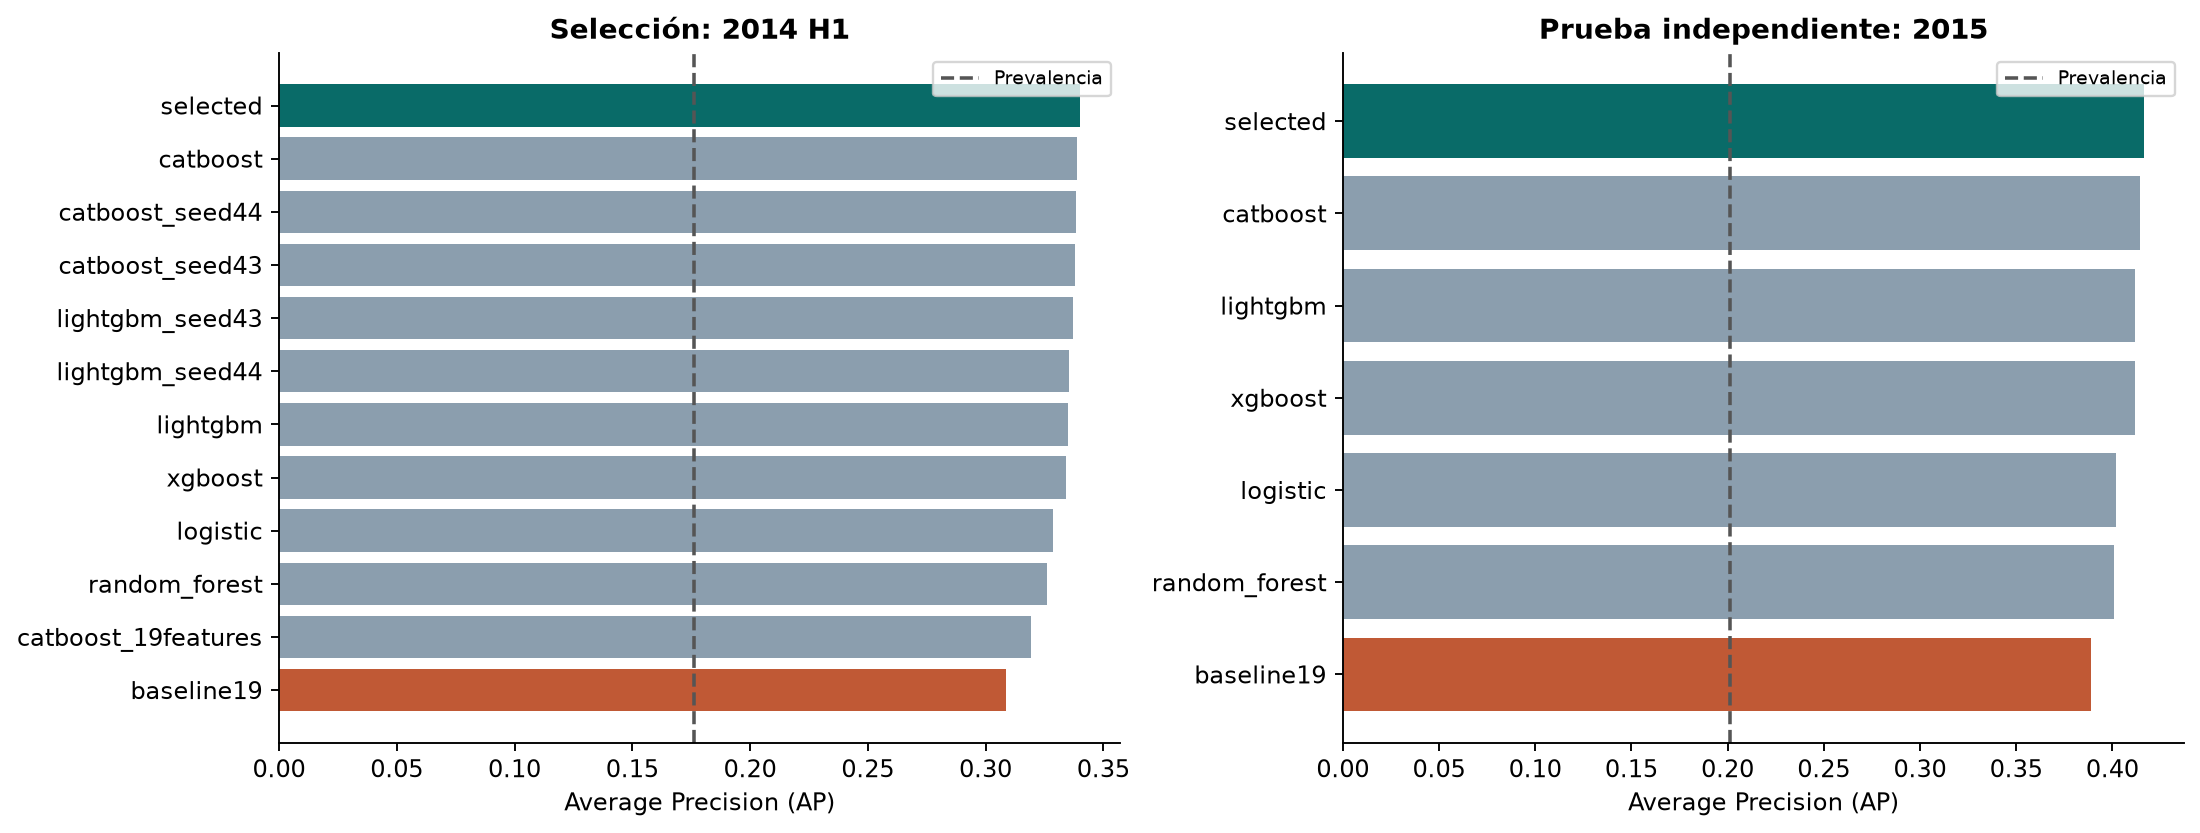

In [5]:
display(Image(filename=str(OUT/'figures'/'comparacion_modelos.png')))

## Calibración y política de umbral

Después de seleccionar, se reentrena hasta junio de 2014. Identidad, sigmoid e isotonic se ajustan en Q3 y se comparan por Brier en Q4. El umbral F1 se fija en Q4. No se presupone un costo real de rechazar o conceder créditos; los umbrales son referencias experimentales. La AP original del avance aleatorio no es una comparación pareada con estas cohortes.

In [6]:
cal=pd.read_csv(OUT/'calibration_selection.csv')
display(cal[['model','calibration','AP','ROC_AUC','Brier','log_loss']])
lock=json.loads((OUT/'selection_lock.json').read_text(encoding='utf-8'))
print('Congelado UTC:', lock['frozen_utc'])
print('Modelo SHA-256:', lock['model_sha256'])
print('Calibrador seleccionado:', lock['calibration']['selected'])
print('Umbrales:', lock['thresholds']['selected'])

,model,calibration,AP,ROC_AUC,Brier,log_loss
0,logistic,identity,0.371862,0.712436,0.142076,0.447056
1,logistic,sigmoid,0.371862,0.712436,0.141608,0.445828
2,logistic,isotonic,0.364127,0.712004,0.141700,0.446548
3,random_forest,identity,0.366291,0.707364,0.218938,0.627391
4,random_forest,sigmoid,0.366291,0.707364,0.142239,0.447724
5,random_forest,isotonic,0.360023,0.707078,0.142304,0.448206
6,lightgbm,identity,0.376844,0.716592,0.141668,0.445358
7,lightgbm,sigmoid,0.376844,0.716592,0.140992,0.443692
8,lightgbm,isotonic,0.370191,0.716331,0.141023,0.444047
9,xgboost,identity,0.377122,0.716058,0.150057,0.469635


Congelado UTC: 2026-10-27T17:24:46.391421+00:00
Modelo SHA-256: 5261d382d1d11b33ca07b24437bd1db7b3dd08250bd5ccc4280870e458a6fdaa
Calibrador seleccionado: sigmoid
Umbrales: {'f1': 0.20848339818594064, 'recall60': 0.22052834830194312, 'capacity20': 0.29947155592004093, 'default': 0.5}


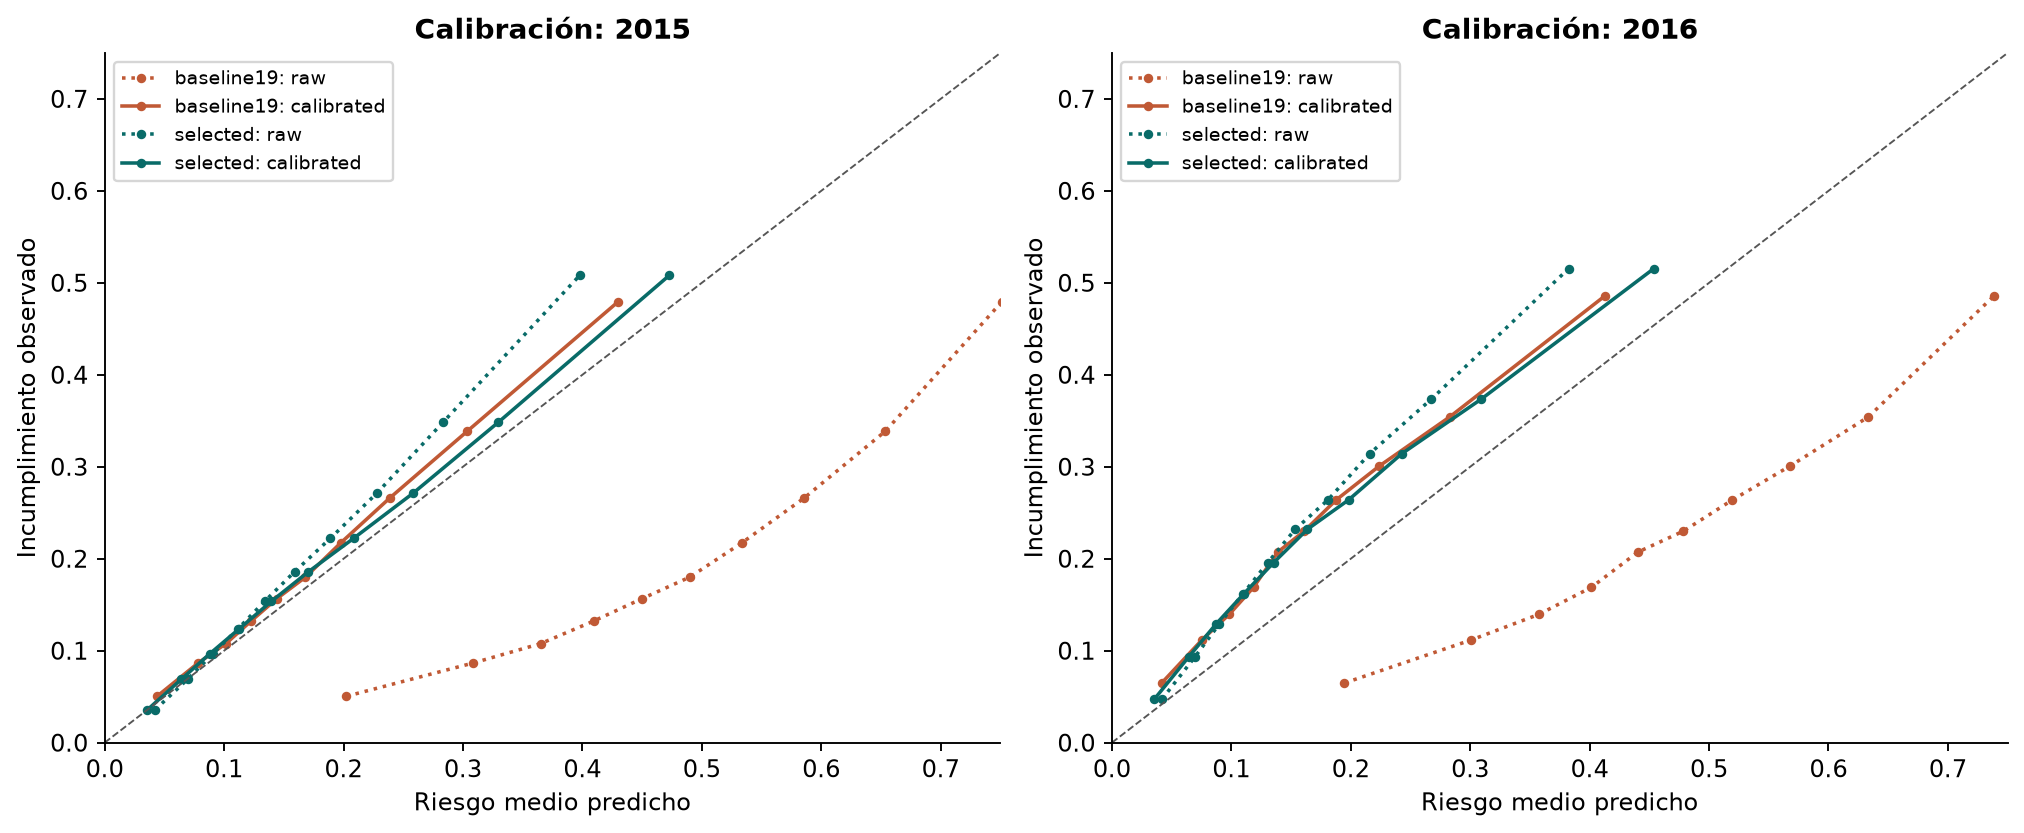

In [7]:
display(Image(filename=str(OUT/'figures'/'calibracion_temporal.png')))

## Evaluación externa por fecha

**Alcance de la evaluación:** clasificación retrospectiva de `Charged Off` frente a `Fully Paid` entre préstamos aceptados con resultado registrado. El split es por fecha de emisión, con IDs externos a la muestra inicial en 2015 y 2016. El snapshot no reconstruye todas las fechas históricas de disponibilidad de las etiquetas. Deben leerse la censura y los plazos junto a las métricas.

Las otras familias se muestran como comparadores congelados. El ganador sigue siendo el elegido en desarrollo aunque otra fila obtenga una métrica mayor en prueba. `AP_raw` permite distinguir discriminación original de empates introducidos por calibración isotónica.

In [8]:
test=pd.read_csv(OUT/'final'/'metrics.csv')
display(test.query("scope == 'all_resolved'")[[ 'cohort','model','n','prevalence','AP','AP_raw','ROC_AUC','Brier','precision','recall','F1']])
display(test.query("model == 'selected'")[[ 'cohort','scope','n','AP','ROC_AUC','Brier','recall_at_top20']])

,cohort,model,n,prevalence,AP,AP_raw,ROC_AUC,Brier,precision,recall,F1
0,2015,baseline19,343507,0.201449,0.389001,0.389001,0.711092,0.145527,0.350917,0.565268,0.433018
3,2015,logistic,343507,0.201449,0.402063,0.402063,0.726442,0.143222,0.355750,0.596887,0.445800
6,2015,random_forest,343507,0.201449,0.400586,0.400586,0.721185,0.143914,0.370694,0.532045,0.436950
9,2015,lightgbm,343507,0.201449,0.411674,0.411674,0.730379,0.142418,0.358525,0.600124,0.448881
12,2015,xgboost,343507,0.201449,0.411535,0.411535,0.730036,0.142433,0.361435,0.591121,0.448586
15,2015,catboost,343507,0.201449,0.414463,0.414463,0.732649,0.141971,0.347656,0.637350,0.449903
18,2015,selected,343507,0.201449,0.416400,0.416400,0.733445,0.141808,0.355603,0.615818,0.450858
21,2016,baseline19,268096,0.232682,0.395785,0.395814,0.687483,0.167793,0.382892,0.481252,0.426474
24,2016,logistic,268096,0.232682,0.406410,0.406409,0.703127,0.165111,0.389683,0.525464,0.447501
27,2016,random_forest,268096,0.232682,0.405522,0.405522,0.695908,0.166787,0.408766,0.422965,0.415744


,cohort,scope,n,AP,ROC_AUC,Brier,recall_at_top20
18,2015,all_resolved,343507,0.416400,0.733445,0.141808,0.425165
19,2015,36_month,258856,0.271797,0.691953,0.118993,0.382028
20,2015,60_month,84651,0.531509,0.678451,0.211576,0.315348
39,2016,all_resolved,268096,0.424774,0.711564,0.163090,0.382071
40,2016,36_month,212482,0.349501,0.695192,0.150466,0.371972
41,2016,60_month,55614,0.536705,0.682942,0.211321,0.318586


In [9]:
records=json.loads((OUT/'final'/'metrics.json').read_text(encoding='utf-8'))
for row in records:
    if row['model']=='selected' and row['scope']=='all_resolved':
        print('Matriz de confusión, cohorte', row['cohort'], 'umbral', round(row['threshold'],4))
        display(pd.DataFrame(row['confusion_matrix'],index=['Real pagado','Real incumplido'],columns=['Predicho pagado','Predicho incumplido']))

Matriz de confusión, cohorte 2015 umbral 0.2085


,Predicho pagado,Predicho incumplido
Real pagado,197086,77222
Real incumplido,26585,42614


Matriz de confusión, cohorte 2016 umbral 0.2085


,Predicho pagado,Predicho incumplido
Real pagado,153029,52686
Real incumplido,28390,33991


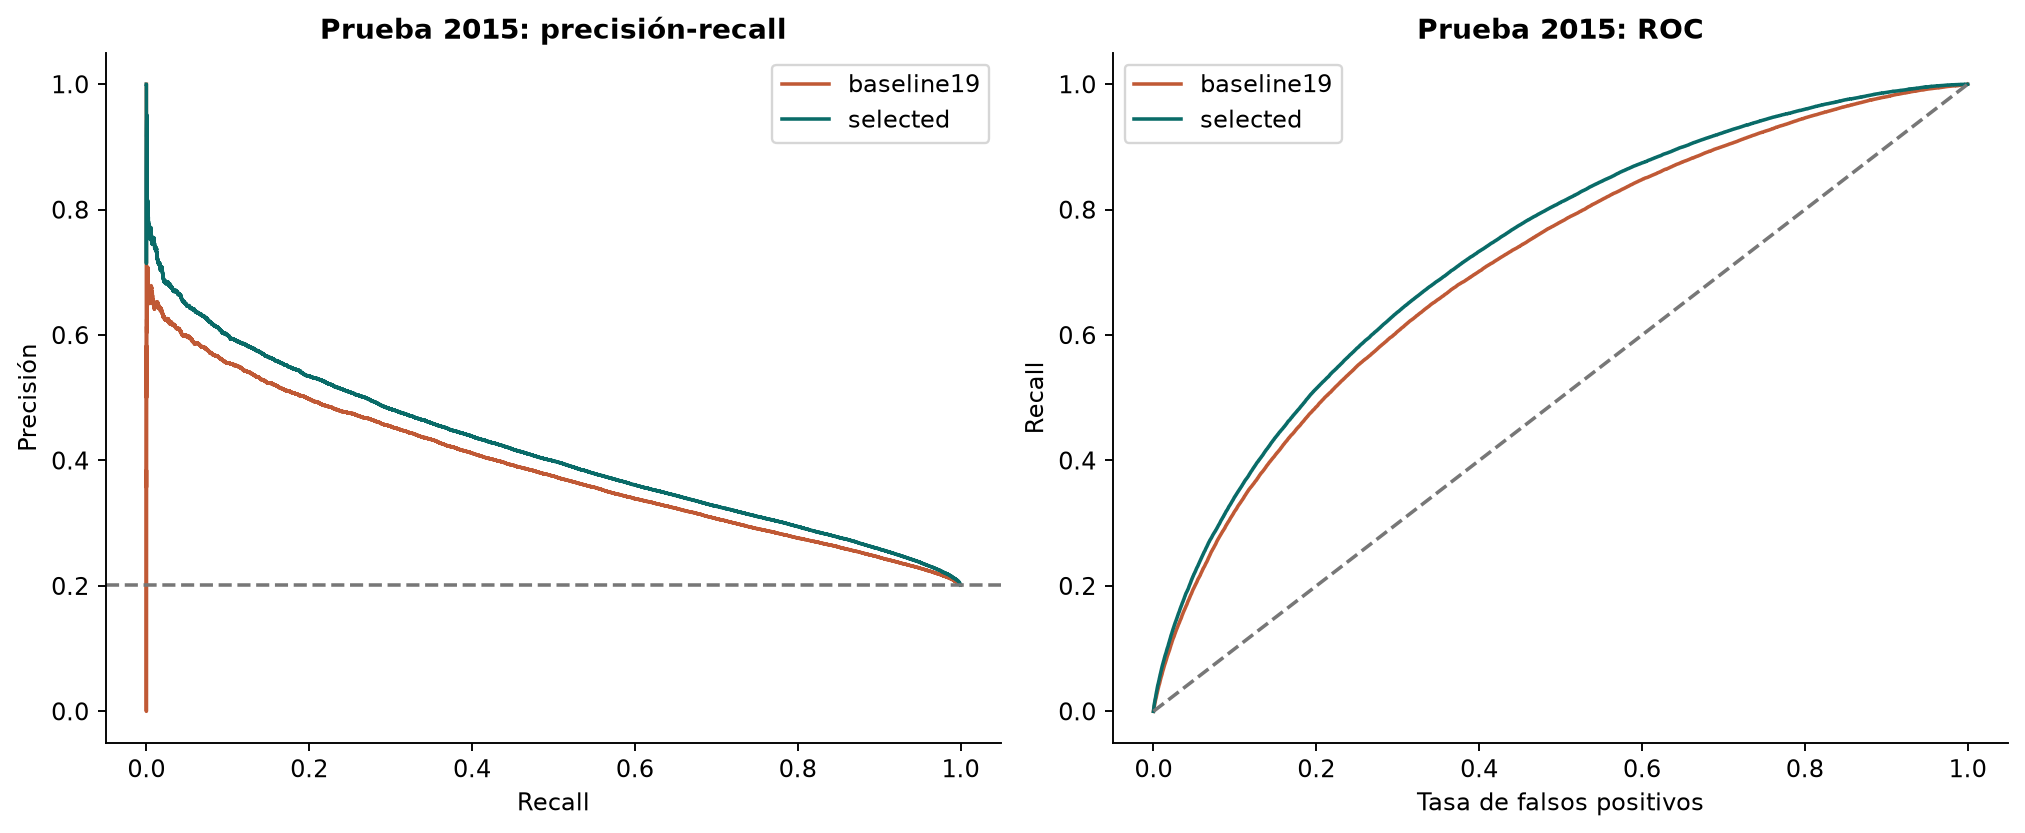

In [10]:
display(Image(filename=str(OUT/'figures'/'curvas_pr_roc.png')))

## Incertidumbre pareada

Se comparan las mismas filas con el baseline reentrenado. Los intervalos por bloques remuestrean meses de emisión completos; solo hay 12 bloques, por lo que no representan toda la incertidumbre macroeconómica. Los intervalos por filas tampoco cubren cambios de institución, política crediticia o población.

In [11]:
uncertainty=json.loads((OUT/'final'/'uncertainty.json').read_text(encoding='utf-8'))
for cohort, estimates in uncertainty.items():
    print(cohort)
    display(pd.DataFrame({kind: values for kind, values in estimates.items()}))
print(json.loads((OUT/'final'/'evaluation_receipt.json').read_text(encoding='utf-8')))

2015_all_resolved


,row,issue_month_block
AP,"{'low': 0.41272240799672566, 'high': 0.4198193...","{'low': 0.40705153715264525, 'high': 0.4248226..."
ROC_AUC,"{'low': 0.7316035639083907, 'high': 0.73523790...","{'low': 0.729599985549878, 'high': 0.737428355..."
Brier,"{'low': 0.1411344891290885, 'high': 0.14267035...","{'low': 0.1396149238230956, 'high': 0.14342621..."
paired_AP_delta_vs_baseline,"{'low': 0.0251723739006983, 'high': 0.02955151...","{'low': 0.024259303539815, 'high': 0.030173706..."
repetitions,300,300


2015_36_month


,row,issue_month_block
AP,"{'low': 0.26757032391687346, 'high': 0.2760600...","{'low': 0.26591972565283184, 'high': 0.2778756..."
ROC_AUC,"{'low': 0.6891663982971843, 'high': 0.69465611...","{'low': 0.6888090820906669, 'high': 0.69417702..."
Brier,"{'low': 0.11816538987193248, 'high': 0.1198583...","{'low': 0.11722888066313138, 'high': 0.1208011..."
paired_AP_delta_vs_baseline,"{'low': 0.030818140036801826, 'high': 0.035899...","{'low': 0.030819491672724745, 'high': 0.035554..."
repetitions,300,300


{'state': 'complete', 'started_utc': '2026-10-27T17:24:56.092972+00:00', 'lock_sha256': '892d430c5601882578ef5619a2b5e92c731c186aab44bc0a5f37339bc09adb42', 'completed_cohorts': [2015, 2016], 'model_selection_already_frozen': True, 'completed_utc': '2026-10-27T17:30:18.772026+00:00', 'selected_model_unchanged': True, 'selected_name': 'ensemble', 'metrics_sha256': '611bc18c681fbda220ba8664235616710b5aa651f4131a19efc30a3c0d78c8bd'}
